# Module 10: A natural river and a managed river

*The code behind GEOS 212: Water in the West, Boise State University*

The Boise River you walk along on the Greenbelt is not a natural river. Upstream of Boise, three dams (Anderson Ranch, Arrowrock and Lucky Peak) together store close to a million acre-feet of water. They catch spring snowmelt, protect Boise from floods, and release water through the summer for irrigation.

In lecture we compared two USGS stream gages:

| Gage | USGS number | Drainage area | What it sees |
|---|---|---|---|
| Boise River near Twin Springs | 13185000 | 832 mi² | above the reservoirs: close to **natural** flow |
| Boise River at Glenwood Bridge | 13206000 | 2,773 mi² | in Boise, below Lucky Peak: **regulated** flow |

This notebook shows the code behind that comparison, and then goes a step further.

**Where are we in the water year?** We are in the *river*: the snowmelt from Module 04 is now streamflow, and people are managing it.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

In [2]:
def water_year(dates):
    """Water year: Oct 1 2025 - Sep 30 2026 is water year 2026."""
    return dates.year + (dates.month >= 10)

def wy_axis_date(dates):
    """Map every date onto one shared 'generic' water year (Oct 2000 - Sep 2001),
    so different years can be drawn on the same x-axis."""
    return pd.to_datetime([pd.Timestamp(2000 if d.month >= 10 else 2001, d.month, min(d.day, 28) if d.month == 2 else d.day)
                           for d in dates])

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

## 2. Getting the streamflow data

A USGS stream gage records water level (*stage*) every 15 minutes. USGS converts stage to discharge with a **rating curve** (you'll build one by hand on the stream gaging field trip!), then publishes daily mean discharge in cubic feet per second (cfs). The function below downloads those daily values from the USGS National Water Information System (NWIS). The site number, the variable code (`00060` = discharge) and the dates are all right there in the URL.

In [3]:
def get_usgs_daily_flow(site, start, end):
    """Daily mean discharge (cubic feet per second, cfs) from USGS NWIS.
    Returns a pandas Series indexed by date."""
    url = ("https://waterservices.usgs.gov/nwis/dv/?format=rdb"
           f"&sites={site}&parameterCd=00060&statCd=00003&startDT={start}&endDT={end}")
    text = fetch_text(url, f"usgs_{site}_{start}_{end}.rdb")
    # USGS "rdb" files are tab-separated, with '#' comment lines and a
    # second header row that describes column widths (we skip it).
    df = pd.read_csv(io.StringIO(text), sep="\t", comment="#", dtype=str).iloc[1:]
    flow_col = [c for c in df.columns if c.endswith("_00060_00003")][0]
    q = pd.to_numeric(df[flow_col], errors="coerce")   # turns codes like 'Ice' into NaN
    q.index = pd.to_datetime(df["datetime"])
    return q.dropna().rename("Q_cfs")

In [4]:
GAGES = {"13185000": "Twin Springs (natural)", "13206000": "Glenwood Bridge (regulated)"}
flows = {site: get_usgs_daily_flow(site, "2022-10-01", "2026-09-30") for site in GAGES}

# Put both gages side by side in one table, one row per day
q = pd.DataFrame(flows).rename(columns=GAGES)
q = q[~((q.index.month == 2) & (q.index.day == 29))]     # drop leap days
q["wy"] = water_year(q.index)
q.tail()

Downloaded live data -> usgs_13185000_2022-10-01_2026-09-30.rdb


Downloaded live data -> usgs_13206000_2022-10-01_2026-09-30.rdb


,Twin Springs (natural),Glenwood Bridge (regulated),wy
datetime,,,
2026-09-26,304,555,2026
2026-09-27,308,559,2026
2026-09-28,309,483,2026
2026-09-29,306,386,2026
2026-09-30,305,396,2026


> **Note:** WY2026 values (Oct 2025 - Sep 2026) are *provisional*: USGS may still revise them.

## 3. Natural vs. regulated hydrographs

Let's plot both gages for a snowy year (WY2023) and a snow-drought year (WY2026, see Module 04).

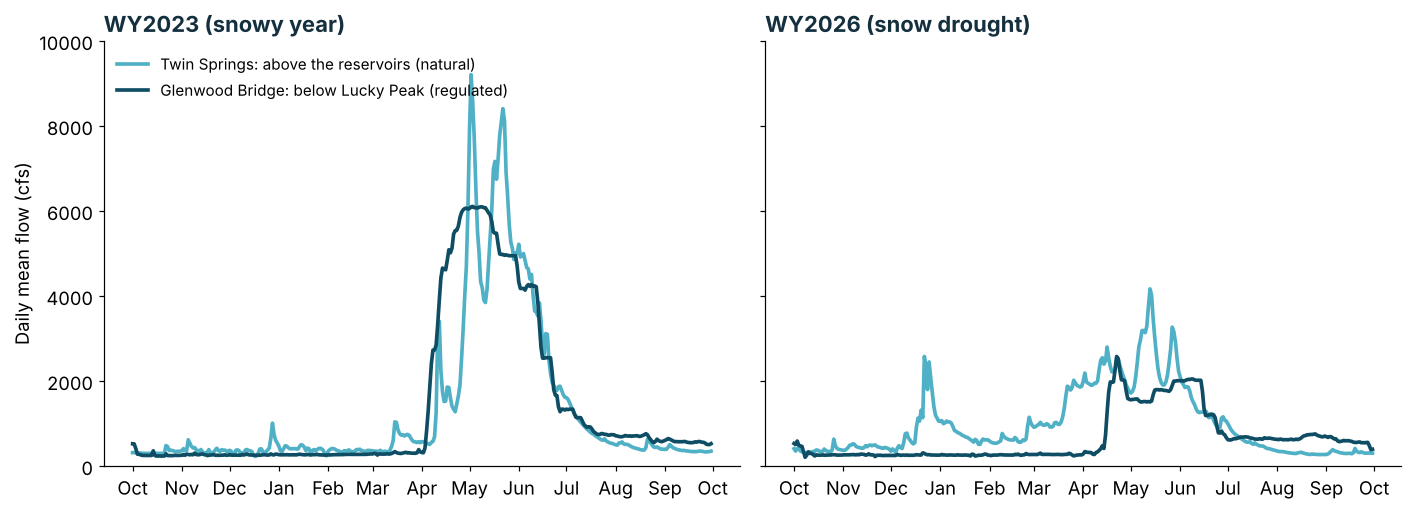

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, wy in zip(axs, [2023, 2026]):
    d = q[q.wy == wy]
    x = wy_axis_date(d.index)
    ax.plot(x, d["Twin Springs (natural)"], color=GLACIER, lw=2.4, label="Twin Springs: above the reservoirs (natural)")
    ax.plot(x, d["Glenwood Bridge (regulated)"], color=DEEP, lw=2.4, label="Glenwood Bridge: below Lucky Peak (regulated)")
    month_axis(ax)
    ax.set_title(f"WY{wy}" + (" (snowy year)" if wy == 2023 else " (snow drought)"), loc="left", fontweight="bold", color=INK)
    ax.set_ylim(0, 10000)
axs[0].set_ylabel("Daily mean flow (cfs)")
axs[0].legend(frameon=False, loc="upper left", fontsize=10)
plt.tight_layout()

**Things to notice:**

* Glenwood drains more than three times the area of Twin Springs, yet in May 2023 its peak was about a third *lower* (roughly 6,100 vs 9,200 cfs) and flat-topped. Where did the rest of the snowmelt go? (Into the reservoirs.)
* In early April 2023, Glenwood ran *higher* than Twin Springs. Managers released water early to make room for the melt they expected from the big snowpack (that's why April 1 SWE forecasts matter so much!).
* Through fall and winter, Glenwood sits nearly flat at a low, steady release while the reservoirs refill.
* In late summer, Glenwood stays above natural flow: stored water is being released for irrigators and the river. (Much more is taken out by canals upstream of Glenwood, so this gage doesn't see all of it.)
* In December 2025, the warm rain-on-snow runoff we saw in Module 04 shows up at Twin Springs, but the reservoirs catch it before it reaches Boise.

## 4. Going further: do the reservoirs make the river steadier?

A simple way to measure how "flashy" a river is: compare its highest flow to its lowest. Let's compute, for each water year, the peak daily flow, the lowest daily flow, and their ratio at each gage.

In [6]:
stats = q.groupby("wy").agg(["max", "min"])
summary = pd.DataFrame({
    "Twin Springs peak (cfs)": stats[("Twin Springs (natural)", "max")],
    "Twin Springs low (cfs)": stats[("Twin Springs (natural)", "min")],
    "Glenwood peak (cfs)": stats[("Glenwood Bridge (regulated)", "max")],
    "Glenwood low (cfs)": stats[("Glenwood Bridge (regulated)", "min")],
})
summary["Twin Springs peak/low"] = (summary["Twin Springs peak (cfs)"] / summary["Twin Springs low (cfs)"]).round(1)
summary["Glenwood peak/low"] = (summary["Glenwood peak (cfs)"] / summary["Glenwood low (cfs)"]).round(1)
summary

,Twin Springs peak (cfs),Twin Springs low (cfs),Glenwood peak (cfs),Glenwood low (cfs),Twin Springs peak/low,Glenwood peak/low
wy,,,,,,
2023,9210,228,6110,236,40.4,25.9
2024,5170,254,3920,199,20.4,19.7
2025,5950,246,4780,223,24.2,21.4
2026,4170,271,2580,208,15.4,12.4


The reservoirs clearly cut the peaks. But peak-to-low is crude because it depends on just two days. A **flow duration curve** uses *every* day: sort all the daily flows from highest to lowest and plot each one against the percent of time that flow is equaled or exceeded. The left end of the curve shows the floods; the right end shows the low flows. Hydrologists use these curves to design water intakes, set minimum flows for fish, and size hydropower plants.

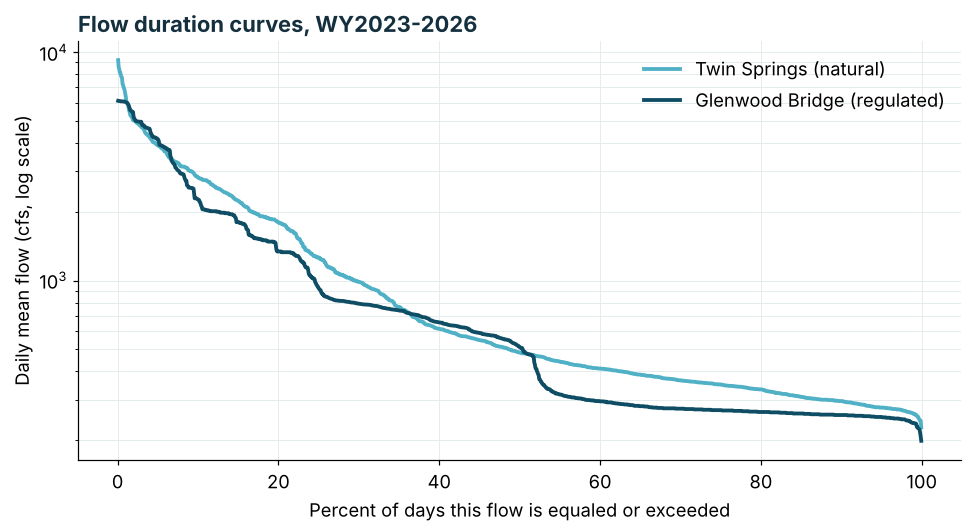

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for col, color in [("Twin Springs (natural)", GLACIER), ("Glenwood Bridge (regulated)", DEEP)]:
    sorted_q = np.sort(q[col].dropna().values)[::-1]          # highest to lowest
    exceed = 100 * np.arange(1, len(sorted_q) + 1) / (len(sorted_q) + 1)
    ax.plot(exceed, sorted_q, color=color, lw=2.5, label=col)
ax.set_yscale("log")
ax.set_xlabel("Percent of days this flow is equaled or exceeded")
ax.set_ylabel("Daily mean flow (cfs, log scale)")
ax.set_title("Flow duration curves, WY2023-2026", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False)
ax.grid(True, which="both", color="#E3EBEC", lw=0.6)
plt.tight_layout()

**Read the curves carefully. The answer is "yes and no."** The regulated curve is lower at the left end (peaks are cut), but look at the sharp drop near 50%: on about half of all days, Glenwood runs at a low, nearly constant release, *below* what the natural river would carry. Managing a river for floods and irrigation doesn't just smooth it; it moves water from one season to another. Who benefits from that, and who (or what: think fish and riverside cottonwoods) might not?

## 5. Your turn

1. **Annual volume.** Using the `CFS_DAY_TO_AF = 1.9835` conversion from the Module 04 notebook, compute each water year's total flow volume (in acre-feet) at both gages. Glenwood's drainage area is 3.3 times Twin Springs'. Is its volume 3.3 times bigger? Where might the "missing" water go? (Think: canal diversions upstream of Glenwood, evaporation from reservoirs, and water still stored at the end of the year.)
2. **A longer record.** Change the start date to `"1990-10-01"` and redo the flow duration curves. Do four years tell the same story as 36?
3. **Another river.** The Payette River near Horseshoe Bend (USGS 13247500) is below Cascade and Deadwood reservoirs. Swap it in. Is it more or less regulated than the Boise?

### Why code?
The same 20 lines download and compare *any* two of the roughly 10,000 USGS stream gages with daily data. Changing the years, the gages, or the statistic is a one-word edit, and every step is written down for someone else to check.

---
*Data: USGS National Water Information System, daily values. WY2026 data are provisional.*